In [28]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [29]:
image = cv2.imread('sar_4.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

In [30]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    
    if abs(float(av_val) - float(img[point])) <= T:
        return True
    
    return False

In [31]:
def region_growing(image, seed_point, homo_fun, r, T, verbose=False):
    mask = np.zeros(image.shape[:2], np.uint8)   # <-- исправлено
    mask[seed_point] = 1
    count = 1
    iteration = 0
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape[:2], np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i-r:i+r+1, j-r:j+r+1].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        if verbose:
            print(f"Итерация {iteration}: добавлено {count} пикселей")
        mask += local_mask
        iteration += 1
    return mask * 255

Text(0.5, 1.0, 'Исходное изображение с seed')

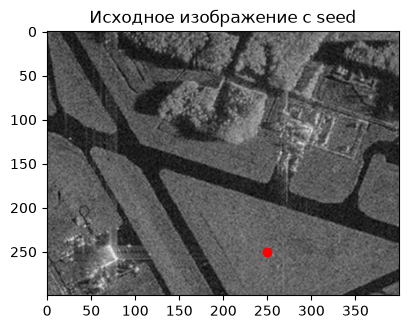

In [32]:
seed_point_lawn = (250, 250)  

r_lawn = 2
T_lawn = 24  

mask_lawn = region_growing(image_gray, seed_point_lawn, homo_average, r_lawn, T_lawn)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.plot(seed_point_lawn[1], seed_point_lawn[0], 'ro')  # Отметим seed
plt.title('Исходное изображение с seed')

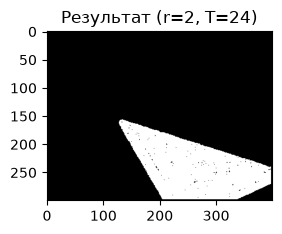

In [33]:
plt.subplot(1, 2, 2)
plt.imshow(mask_lawn, cmap='gray')
plt.title(f'Результат (r={r_lawn}, T={T_lawn})')
plt.show()

Text(0.5, 1.0, 'Среднее (T=24)')

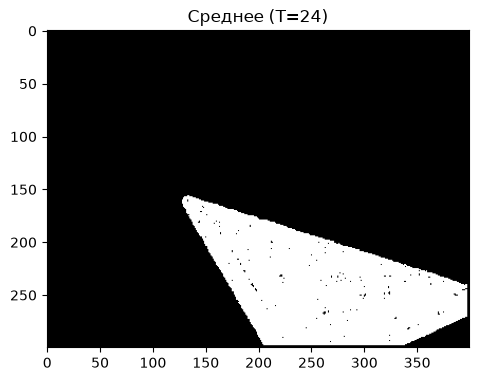

In [34]:
def homo_median(img, mask, point, T):
    values_in_mask = img[mask > 0]
    if len(values_in_mask) == 0:
        return True
    median_val = np.median(values_in_mask)
    return abs(float(median_val) - float(img[point])) <= T

T_median = 25 
mask_median = region_growing(image_gray, seed_point_lawn, homo_median, r_lawn, T_median)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(mask_lawn, cmap='gray')
plt.title(f'Среднее (T={T_lawn})')

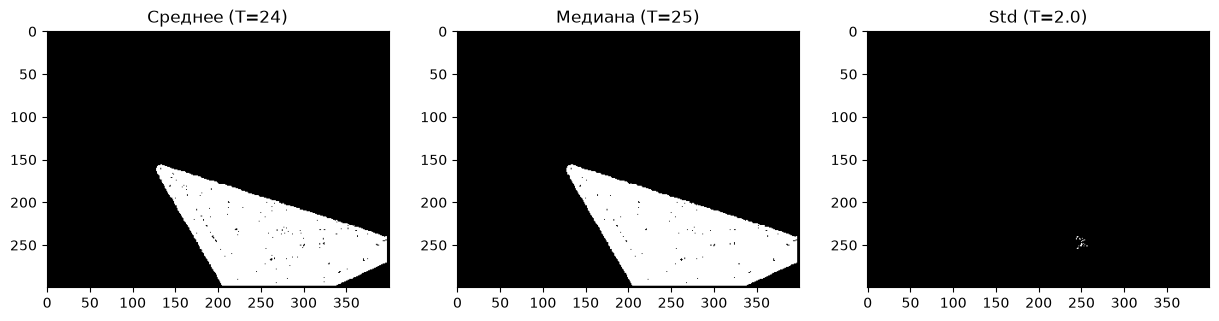

In [35]:
def homo_std(img, mask, point, T):
    """
    Критерий однородности на основе стандартного отклонения.
    T здесь - это коэффициент, на который умножается std.
    """
    values_in_mask = img[mask > 0]
    
    if len(values_in_mask) < 2:
        if len(values_in_mask) == 0:
            return True
        av_val = values_in_mask[0]
        return abs(float(av_val) - float(img[point])) <= T
    
    mean_val = np.mean(values_in_mask)
    std_val = np.std(values_in_mask)
    if abs(mean_val - img[point]) <= T * std_val:
        return True
    
    return False

T_std = 2.0 
mask_std = region_growing(image_gray, seed_point_lawn, homo_std, r_lawn, T_std)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask_lawn, cmap='gray')
plt.title(f'Среднее (T={T_lawn})')

plt.subplot(1, 3, 2)
plt.imshow(mask_median, cmap='gray')
plt.title(f'Медиана (T={T_median})')

plt.subplot(1, 3, 3)
plt.imshow(mask_std, cmap='gray')
plt.title(f'Std (T={T_std})')

plt.show()

Количество обнаруженных пальм: 85


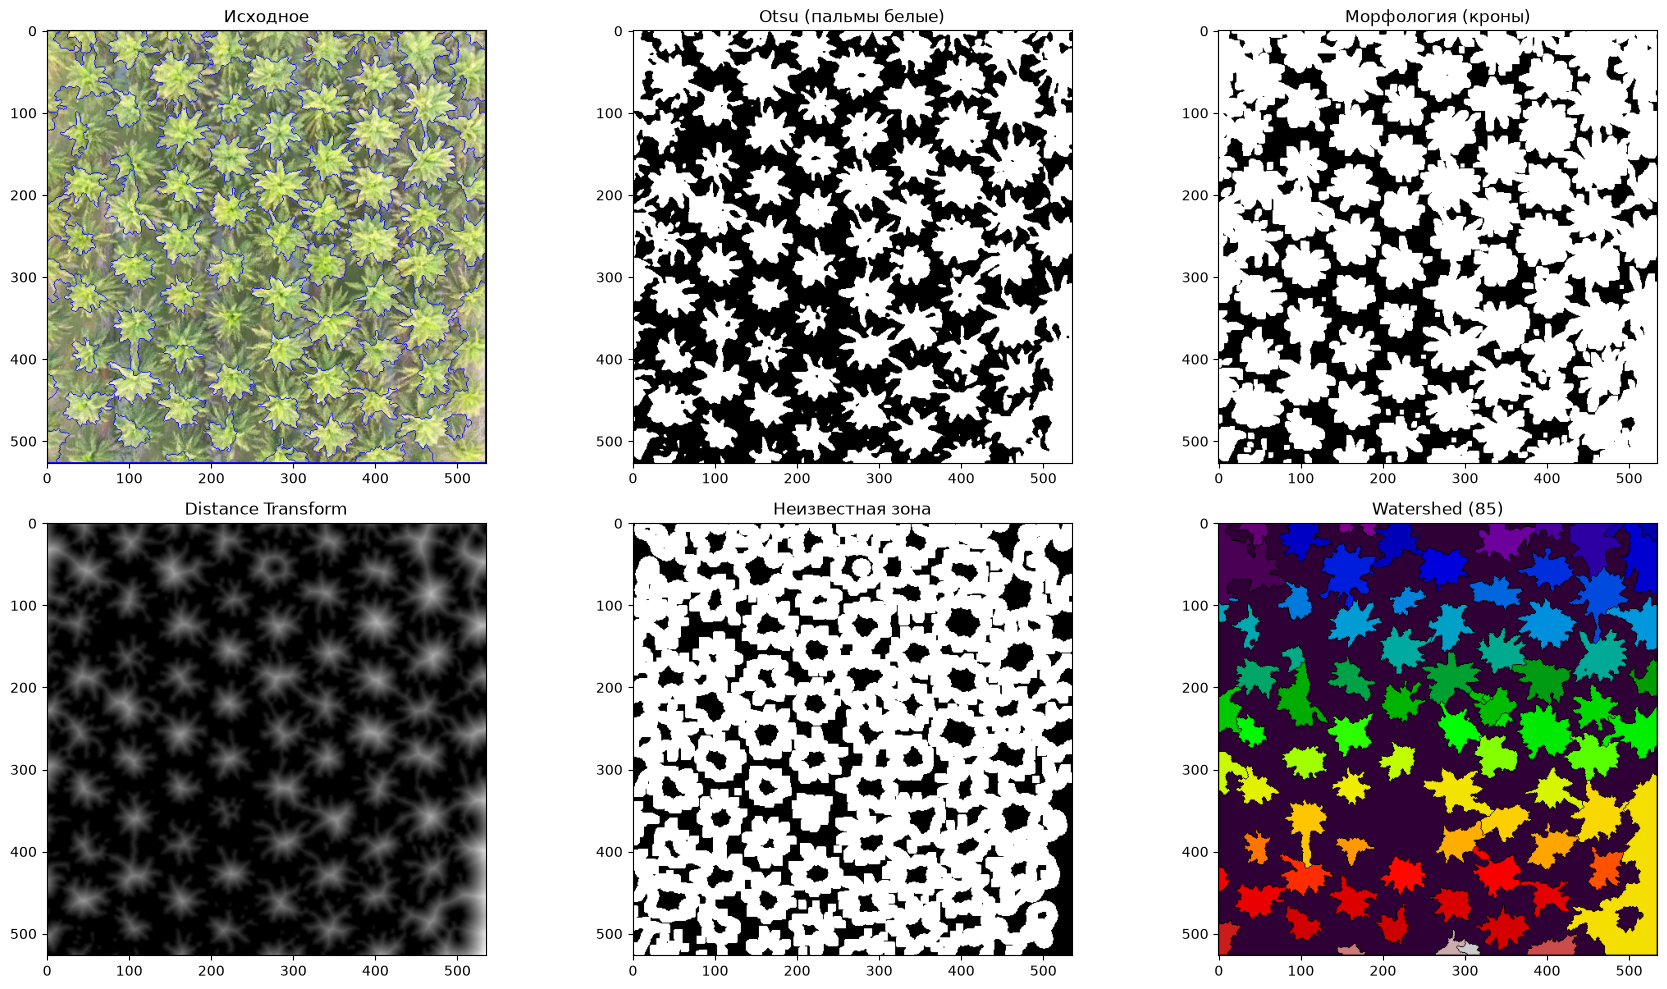

In [36]:
image_palms = cv2.imread('palm_1.jpg')  
gray = cv2.cvtColor(image_palms, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray, (11, 11), 0)

_, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)
dilated = cv2.dilate(thresh, kernel, iterations=1)
opening = cv2.morphologyEx(dilated, cv2.MORPH_OPEN, kernel, iterations=1)

dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

ret, sure_fg = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

sure_bg = cv2.dilate(opening, kernel, iterations=1)

unknown = cv2.subtract(sure_bg, sure_fg)

ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1          
markers[unknown == 255] = 0    

markers = cv2.watershed(image_palms, markers)
image_palms[markers == -1] = [255, 0, 0]  

unique_markers = np.unique(markers)
object_markers = [m for m in unique_markers if m != 1 and m != -1]
count = len(object_markers)
print(f"Количество обнаруженных пальм: {count}")

plt.figure(figsize=(18, 10))

plt.subplot(2, 3, 1); plt.imshow(cv2.cvtColor(image_palms, cv2.COLOR_BGR2RGB)); plt.title('Исходное')
plt.subplot(2, 3, 2); plt.imshow(thresh, cmap='gray'); plt.title('Otsu (пальмы белые)')
plt.subplot(2, 3, 3); plt.imshow(opening, cmap='gray'); plt.title('Морфология (кроны)')
plt.subplot(2, 3, 4); plt.imshow(dist_transform, cmap='gray'); plt.title('Distance Transform')
plt.subplot(2, 3, 5); plt.imshow(unknown, cmap='gray'); plt.title('Неизвестная зона')
plt.subplot(2, 3, 6); plt.imshow(markers, cmap='nipy_spectral'); plt.title(f'Watershed ({count})')

plt.tight_layout()
plt.show()